In [14]:
import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

import arviz as az
import arviz_plots as azp

## Generate data

In [15]:
def generate_data(n_tanks=50,
                  sigma=2.0, 
                  alpha=0.8, 
                  tau=0.5, 
                  c=3.0, 
                  gamma=0.4, 
                  delta=0.5, 
                  seed=42,):
    
    rng = np.random.default_rng(seed)

    V = rng.uniform(50, 200, size=n_tanks)

    V0 = 100.0
    v = V / V0

    b = rng.normal(0, tau, size=n_tanks)
    beta = np.exp(b)

    lambda_ = sigma * v**alpha * beta

    counts = rng.poisson(lambda_)

    mean_leak = c * v**gamma * beta**delta

    leak_sizes = []
    leak_tank_id = []

    for i in range(n_tanks):
        sizes = rng.exponential(
            scale=mean_leak[i],
            size=counts[i],
        )

        leak_sizes.extend(sizes)
        leak_tank_id.extend([i] * counts[i])

    return {
        "V": V,
        "counts": counts,
        "leak_sizes": np.asarray(leak_sizes),
        "leak_tank_id": np.asarray(leak_tank_id),

        # Ground truth
        "true_beta": beta,
        "true_b": b,
        "true_lambda": lambda_,
        "true_mean_leak": mean_leak,
    }

In [16]:
true_sigma = 2.0
true_alpha = 0.8
true_tau = 0.5

true_c = 3.0
true_gamma = 0.4

true_delta = 0.7

data = generate_data(
    sigma=true_sigma,
    alpha=true_alpha,
    tau=true_tau,
    c=true_c,
    gamma=true_gamma,
    delta=true_delta,
)

In [ ]:
def model(V, counts, leak_sizes, leak_tank_id):

    n_tanks = len(V)

    V0 = 100.0
    v = V / V0

    sigma = numpyro.sample("sigma", dist.LogNormal(0.0, 1.0))
    alpha = numpyro.sample("alpha", dist.Normal(0.0, 1.0))
    tau = numpyro.sample("tau", dist.HalfNormal(1.0))

    with numpyro.plate("tanks", n_tanks):
        b = numpyro.sample("b", dist.Normal(0.0, tau))

    beta = jnp.exp(b)

    lambda_ = (sigma * v**alpha * beta)

    with numpyro.plate("tank_counts", n_tanks):
        numpyro.sample("counts", dist.Poisson(lambda_), obs=counts)


    c = numpyro.sample("c",dist.LogNormal(0.0, 1.0))

    gamma = numpyro.sample("gamma", dist.Normal(0.0, 1.0))
    delta = numpyro.sample("delta", dist.Normal(0.0, 1.0))

    mean_leak = (c * v**gamma * beta**delta)

    leak_mean = mean_leak[leak_tank_id]

    with numpyro.plate("leaks", len(leak_sizes)):
        numpyro.sample("leak_sizes", dist.Exponential(1.0 / leak_mean), obs=leak_sizes)

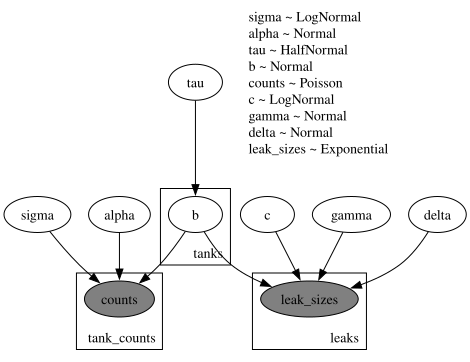

In [5]:
numpyro.render_model(model,
                     model_kwargs={"V": jnp.asarray(data["V"]),
                                   "counts": jnp.asarray(data["counts"]),
                                   "leak_sizes": jnp.asarray(data["leak_sizes"]),
                                   "leak_tank_id": jnp.asarray(data["leak_tank_id"]),},
                    render_distributions=True,)

In [6]:
print("Number of tanks:", len(data["V"]))
print("Total number of leaks:", data["counts"].sum())
print("Number of leak sizes:", len(data["leak_sizes"]))

print()
print("First tank volumes:")
print(data["V"][:5])

print()
print("First leak counts:")
print(data["counts"][:5])

print()
print("First leak sizes:")
print(data["leak_sizes"][:10])

Number of tanks: 50
Total number of leaks: 121
Number of leak sizes: 121

First tank volumes:
[166.09340728 115.83176596 178.78968799 154.60520436  64.12660218]

First leak counts:
[7 0 4 6 1]

First leak sizes:
[ 0.05197352  7.52888009  1.65576628  3.2282119   4.04997358  0.83807004
 13.67077016  2.28933922  0.31567045  0.45248653]


In [7]:
kernel = NUTS(model)

mcmc = MCMC(
    kernel,
    num_warmup=1000,
    num_samples=2000,
    num_chains=1,
)

mcmc.run(
    jax.random.PRNGKey(0),
    V=jnp.asarray(data["V"]),
    counts=jnp.asarray(data["counts"]),
    leak_sizes=jnp.asarray(data["leak_sizes"]),
    leak_tank_id=jnp.asarray(data["leak_tank_id"]),
)

sample: 100%|██████████| 3000/3000 [00:01<00:00, 1646.15it/s, 63 steps of size 1.04e-01. acc. prob=0.96]


In [8]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      0.79      0.32      0.79      0.29      1.33   1197.17      1.00
      b[0]      0.37      0.35      0.32     -0.14      0.95    168.03      1.00
      b[1]     -0.26      0.39     -0.20     -0.88      0.34    372.08      1.00
      b[2]      0.07      0.33      0.04     -0.42      0.65   1145.45      1.00
      b[3]      0.27      0.35      0.23     -0.25      0.86    202.80      1.00
      b[4]     -0.06      0.36     -0.05     -0.64      0.53   1767.02      1.00
      b[5]     -0.22      0.35     -0.18     -0.77      0.34    617.72      1.00
      b[6]     -0.07      0.31     -0.05     -0.58      0.44   2798.29      1.00
      b[7]     -0.32      0.41     -0.24     -0.94      0.31    242.97      1.00
      b[8]     -0.07      0.37     -0.05     -0.71      0.49   1899.25      1.00
      b[9]      0.26      0.39      0.21     -0.34      0.92    477.44      1.00
     b[10]      0.11      0

In [9]:
samples = mcmc.get_samples()

parameters = {
    "sigma": true_sigma,
    "alpha": true_alpha,
    "tau": true_tau,
    "c": true_c,
    "gamma": true_gamma,
    "delta": true_delta,
}

for name, true_value in parameters.items():
    posterior_mean = samples[name].mean()

    print(
        f"{name:6s} | "
        f"true = {true_value:6.3f} | "
        f"posterior mean = {posterior_mean:6.3f}"
    )

sigma  | true =  2.000 | posterior mean =  1.825
alpha  | true =  0.800 | posterior mean =  0.794
tau    | true =  0.500 | posterior mean =  0.377
c      | true =  3.000 | posterior mean =  3.580
gamma  | true =  0.400 | posterior mean =  0.211
delta  | true =  0.700 | posterior mean =  0.198


In [10]:
import arviz as az
idata = az.from_numpyro(mcmc)

In [11]:
posterior_samples = mcmc.get_samples()
idata = az.from_numpyro(mcmc)

AttributeError: module 'arviz' has no attribute 'plot_posterior'

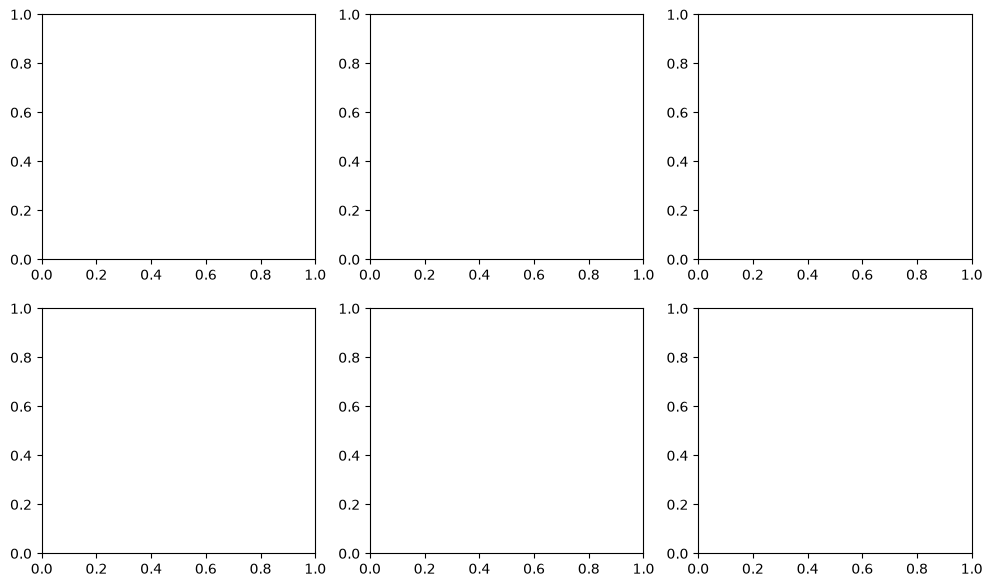

In [12]:
true_values = {
    "sigma": true_sigma,
    "alpha": true_alpha,
    "tau": true_tau,
    "c": true_c,
    "gamma": true_gamma,
    "delta": true_delta,
}

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 7),
)

axes = axes.flatten()

for ax, (name, true_value) in zip(axes, true_values.items()):

    az.plot_posterior(
        idata,
        var_names=[name],
        ax=ax,
    )

    ax.axvline(
        true_value,
        color="black",
        linestyle="--",
        label="True value",
    )

    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
azp.plot_pair(
    idata,
    var_names=[
        "sigma",
        "alpha",
        "tau",
        "c",
        "gamma",
        "delta",
    ],
)

plt.gcf().set_size_inches(12, 12)
plt.show()

In [ ]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 7),
)

axes = axes.flatten()

for ax, (name, true_value) in zip(axes, true_values.items()):

    values = np.asarray(posterior_samples[name])

    ax.hist(
        values,
        bins=40,
        density=True,
        alpha=0.7,
    )

    ax.axvline(
        true_value,
        color="black",
        linestyle="--",
        linewidth=2,
        label="True value",
    )

    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
posterior_beta = np.exp(
    np.asarray(posterior_samples["b"])
)

true_beta = np.asarray(data["true_beta"])

n_tanks = len(true_beta)

In [ ]:
n_cols = 5
n_rows = int(np.ceil(n_tanks / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 2.5 * n_rows),
)

axes = np.asarray(axes).flatten()

for i in range(n_tanks):

    ax = axes[i]

    ax.hist(
        posterior_beta[:, i],
        bins=30,
        density=True,
        alpha=0.7,
    )

    ax.axvline(
        true_beta[i],
        color="black",
        linestyle="--",
        linewidth=2,
        label="True beta",
    )

    ax.set_title(f"Tank {i}")
    ax.set_xlabel(r"$\beta_i$")

# Leere Subplots entfernen
for i in range(n_tanks, len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
beta_mean = posterior_beta.mean(axis=0)

beta_lower = np.quantile(
    posterior_beta,
    0.05,
    axis=0,
)

beta_upper = np.quantile(
    posterior_beta,
    0.95,
    axis=0,
)

tank_id = np.arange(n_tanks)

In [ ]:
plt.figure(figsize=(12, 6))

plt.errorbar(
    tank_id,
    beta_mean,
    yerr=[
        beta_mean - beta_lower,
        beta_upper - beta_mean,
    ],
    fmt="o",
    capsize=3,
    label="Posterior 90% interval",
)

plt.scatter(
    tank_id,
    true_beta,
    marker="x",
    s=50,
    label="True beta",
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Tank")
plt.ylabel(r"$\beta_i$")
plt.title("Tank-specific failure parameters")

plt.legend()
plt.tight_layout()
plt.show()

In [13]:
import arviz as az
print(az.__version__)

1.3.0
